# Cooler stars keep better time

## Part 1: measuring how much a star's rotation period wanders

A spotted star gets brighter and dimmer as it turns, because its spots rotate in and out of view. The time between two dips is the rotation period. TESS watches each strip of sky for about 27 days at a time (one *sector*) and comes back months or years later, so for many stars the period can be measured again and again.

It never comes out exactly the same twice. In this project the sector-to-sector scatter is called the **wander**. Some of it is measurement noise. The rest comes from the star: spots appear, fade and drift, and if the star has differential rotation (equator faster than the poles, as on the Sun), spots at different latitudes give slightly different periods.

The question is how the wander changes with temperature, from Sun-like stars near 6,000 K down to M dwarfs at 3,000 K. Below about 3,400 K, M dwarfs are fully convective: they have no radiative core, and dynamo theory predicts much weaker differential rotation in them. The observations disagree with each other. Doppler imaging of a few dozen young stars finds differential rotation falling steeply toward cooler stars (Barnes et al. 2005; Collier Cameron 2007), while Kepler stars with two close periods show an almost flat trend (Reinhold et al. 2013). Kepler saw very few stars below 3,500 K, so the fully convective boundary itself had not been covered by a large sample.

This notebook builds the measurement step by step on two example stars and then runs it on all 872 stars. [Part 2](2_results.ipynb) looks at what comes out.

In [1]:
import sys
sys.path.insert(0, "..")

import os
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, NullFormatter
from astropy.timeseries import LombScargle

import wander as w

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def plain_log_axis(ax, ticks):
    """Log y axis labelled 0.01, 0.02 ... instead of 10^-2, 2x10^-2 ..."""
    ax.set_yscale("log")
    low, high = ax.get_ylim()
    ax.set_yticks(ticks)
    ax.set_ylim(low, high)
    ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(NullFormatter())

# False: read the saved per-star results. True: measure all 872 stars again from the light
# curves (run `python get_data.py` first; about 25 minutes on an 18-core laptop).
RECOMPUTE = False

## 1. The stars

The stars come from the TESS All-Sky Rotation Survey (TARS; Boyle, Bouma & Mann 2026), a catalogue of rotation periods measured from TESS light curves. A star was eligible if it is

- single and unblended: Gaia RUWE ≤ 1.2, no contaminating neighbour, not flagged as a possible binary or as having a doubled period;
- TESS magnitude 12.5 to 15.5, with a catalogue period of 1.5 to 8 days;
- observed in 8 to 16 sectors that pass TARS's own per-sector checks (signal score ≥ 0.90, match probability ≥ 0.80, harmonic probability ≤ 0.20, sector period within 0.7 to 1.3 times the catalogue period).

From that pool, 30 stars were drawn at random in every 200 K slice between 3,000 and 6,000 K, 15 with periods under 3 days and 15 over. Every slice uses the same brightness and period windows, so no slice can end up with slower or fainter stars just because of how it was picked.

The **original sample** (450 stars) was drawn on 1 September 2026, before any light curve was measured. The **replication sample** (422 stars) was drawn later that day from the stars left over, with a different random seed, after writing down the predictions it would have to meet (Part 2, section 5). Two slices ran short of stars: only 22 were left at 3,000 to 3,200 K and 10 at 5,800 to 6,000 K. Both lists are in `data/star_lists/`.

In [2]:
original = pd.DataFrame(w.read_star_list("original_450"))
replication = pd.DataFrame(w.read_star_list("replication_422"))
print(f"original {len(original)} stars, replication {len(replication)} stars, "
      f"in both: {len(set(original.tic_id) & set(replication.tic_id))}")
for name, df in [("original", original), ("replication", replication)]:
    print(f"{name:12s} Tmag {df.tmag.min():.2f} to {df.tmag.max():.2f}, period {df.period.min():.2f} to {df.period.max():.2f} d, "
          f"{df.sectors.min()} to {df.sectors.max()} sectors, {(df.period < 3).sum()} with P < 3 d")

counts = pd.DataFrame({"original": original.groupby("teff_bin_low").size(),
                       "replication": replication.groupby("teff_bin_low").size()})
counts.index = [f"{b}-{b + 200} K" for b in counts.index]
counts.T

original 450 stars, replication 422 stars, in both: 0
original     Tmag 12.50 to 15.49, period 1.50 to 7.96 d, 8 to 16 sectors, 221 with P < 3 d
replication  Tmag 12.50 to 15.49, period 1.50 to 7.92 d, 8 to 16 sectors, 180 with P < 3 d


,3000-3200 K,3200-3400 K,3400-3600 K,3600-3800 K,3800-4000 K,4000-4200 K,4200-4400 K,4400-4600 K,4600-4800 K,4800-5000 K,5000-5200 K,5200-5400 K,5400-5600 K,5600-5800 K,5800-6000 K
original,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30
replication,22,30,30,30,30,30,30,30,30,30,30,30,30,30,10


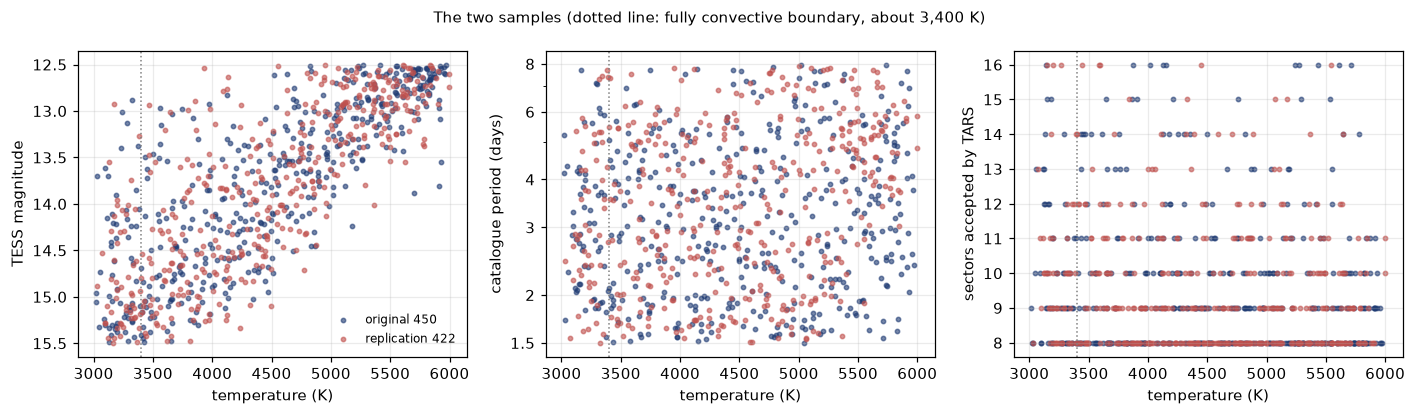

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for df, color, label in [(original, "#1f3b73", "original 450"), (replication, "#c0504d", "replication 422")]:
    axes[0].scatter(df.teff, df.tmag, s=8, color=color, alpha=0.6, label=label)
    axes[1].scatter(df.teff, df.period, s=8, color=color, alpha=0.6)
    axes[2].scatter(df.teff, df.sectors, s=8, color=color, alpha=0.6)
axes[0].set_ylabel("TESS magnitude")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8, frameon=False)
axes[1].set_ylabel("catalogue period (days)")
plain_log_axis(axes[1], [1.5, 2, 3, 4, 6, 8])
axes[2].set_ylabel("sectors accepted by TARS")
for ax in axes:
    ax.set_xlabel("temperature (K)")
    ax.axvline(w.FULLY_CONVECTIVE_TEFF, color="0.5", ls=":", lw=1)
fig.suptitle("The two samples (dotted line: fully convective boundary, about 3,400 K)", fontsize=10)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig1_sample.png", dpi=150)

In [4]:
medians = original.groupby("teff_bin_low")[["tmag", "period", "sectors"]].median().round(2)
medians.index = [f"{b} K" for b in medians.index]
print("original sample, median per slice")
medians.T

original sample, median per slice


,3000 K,3200 K,3400 K,3600 K,3800 K,4000 K,4200 K,4400 K,4600 K,4800 K,5000 K,5200 K,5400 K,5600 K,5800 K
tmag,14.94,14.76,14.81,14.67,14.54,14.27,14.19,13.84,13.52,13.50,13.25,12.91,12.88,12.72,12.63
period,2.95,2.92,2.96,2.98,3.00,3.08,3.00,3.07,3.07,3.04,3.05,3.22,3.13,3.23,3.90
sectors,10.00,9.00,9.00,9.00,8.00,10.00,9.00,9.00,8.00,9.00,9.00,8.00,8.00,8.50,9.00


Period and number of sectors stay about the same from slice to slice (the hottest slice runs a little slower). Brightness does not: the three coolest slices have a median TESS magnitude of about 14.8, the three hottest about 12.7. M dwarfs are intrinsically dim, so the ones TARS can time are mostly near the faint end of the window. Fainter means noisier light curves, and that should make cool stars look *less* steady, which works against the result. It is one reason every star gets its own noise floor in section 5, and why brightness is held fixed in the regression in Part 2.

## 2. One sector of one star

TARS publishes one light-curve file per star per sector on MAST, with the slow instrumental trends already removed. The files for two example stars are in `data/examples/`, so this part runs without downloading anything:

- **TIC 45468124**: 5,558 K, a Sun-like star with a 2.94-day period;
- **TIC 357118805**: 3,372 K, an M dwarf right at the fully convective boundary, with a 1.55-day period.

TESS saw them in almost the same sectors, and they are similar in brightness (TESS magnitude 12.8 and 13.4), so any difference between them is not about when or how well they were observed.

In [5]:
stars = {r["tic_id"]: r for r in w.read_star_list("original_450")}
sun_like, m_dwarf = stars[45468124], stars[357118805]
for star in (sun_like, m_dwarf):
    files = w.sector_files(w.EXAMPLES, star["tic_id"])
    print(f"TIC {star['tic_id']}: {star['teff']:.0f} K, Tmag {star['tmag']:.1f}, catalogue period {star['period']:.4f} d, "
          f"sectors {[w.sector_number(p) for p in files]}")

TIC 45468124: 5558 K, Tmag 12.8, catalogue period 2.9431 d, sectors [8, 9, 10, 35, 36, 37, 62, 63, 89, 90]
TIC 357118805: 3372 K, Tmag 13.4, catalogue period 1.5541 d, sectors [9, 10, 35, 36, 37, 62, 63, 64, 89]


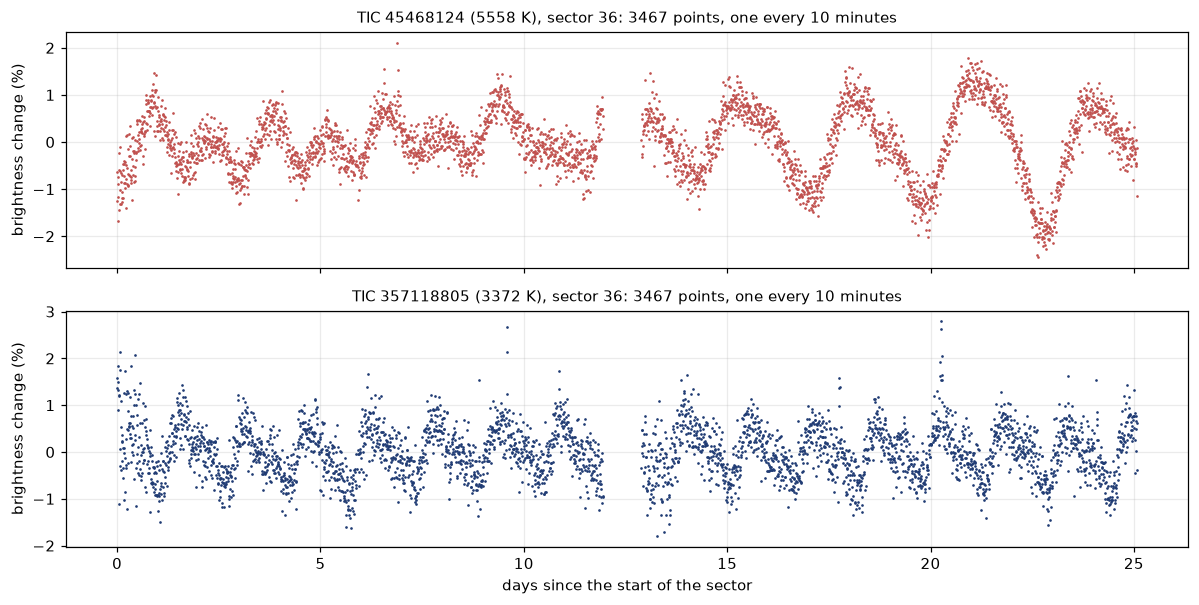

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
for ax, star, color in [(axes[0], sun_like, "#c0504d"), (axes[1], m_dwarf, "#1f3b73")]:
    path = next(p for p in w.sector_files(w.EXAMPLES, star["tic_id"]) if w.sector_number(p) == 36)
    sector, t, f, noise = w.load_sector(path)
    ax.plot(t - t[0], 100 * (f - np.median(f)), ".", ms=1.5, color=color)
    ax.set_ylabel("brightness change (%)")
    ax.set_title(f"TIC {star['tic_id']} ({star['teff']:.0f} K), sector {sector}: {len(t)} points, "
                 f"one every {np.median(np.diff(t)) * 24 * 60:.0f} minutes", fontsize=10)
axes[1].set_xlabel("days since the start of the sector")
fig.tight_layout()
fig.savefig(w.FIGURES / "fig2_light_curves.png", dpi=150)

Each dip is the spotted side of the star turning toward us. The gap in the middle of the sector is where TESS pauses to send its data to Earth. The M dwarf turns almost twice as fast and its wave is a little smaller. The Sun-like star's wave visibly changes shape over the month; the M dwarf's looks much the same from start to end.

## 3. The period in one sector

For each sector, `w.fit_period` removes a straight line, fits a single steady sine wave and keeps its period. It only searches periods between 0.7 and 1.3 times the TARS catalogue period. A star with two large spots on opposite sides makes two dips per turn, and its strongest periodogram peak can then land at half the true period. If the fit jumped to that half-period in some sectors and not in others, it would add fake wander, so the search stays near the catalogue period.

Below: the periodogram of the Sun-like star in sector 36 over a much wider range than the search uses, and the fitted wave on top of the data.

sector 36: period 2.8849 d (catalogue 2.9431 d), amplitude 0.67%, leftover scatter 0.49%


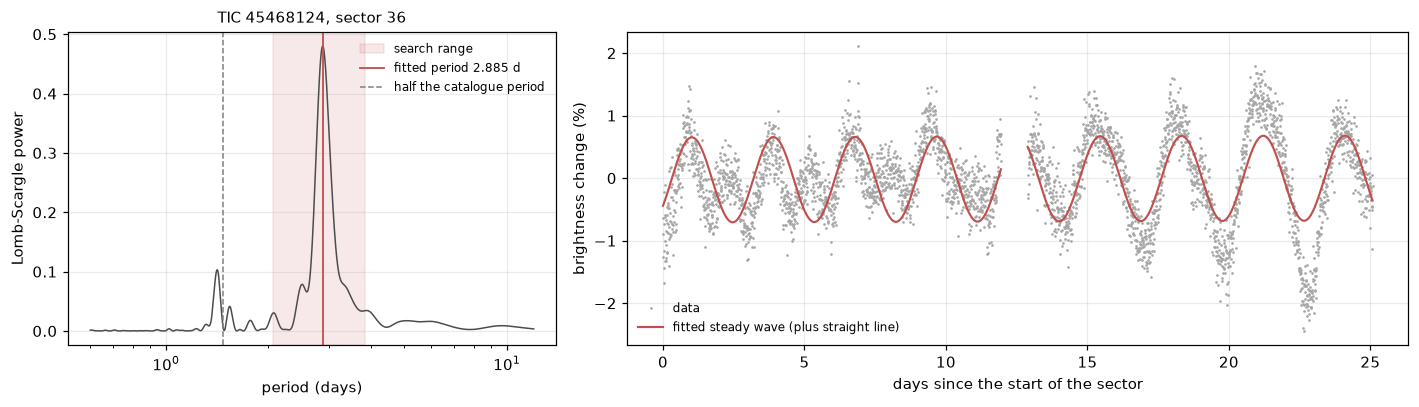

In [7]:
path = next(p for p in w.sector_files(w.EXAMPLES, sun_like["tic_id"]) if w.sector_number(p) == 36)
sector, t, f, noise = w.load_sector(path)
period, amplitude, leftover = w.fit_period(t, f, noise, sun_like["period"])
print(f"sector {sector}: period {period:.4f} d (catalogue {sun_like['period']:.4f} d), "
      f"amplitude {100 * amplitude:.2f}%, leftover scatter {100 * np.std(leftover):.2f}%")

frequency = np.linspace(1 / 12, 1 / 0.6, 5000)
power = LombScargle(t, f - np.median(f)).power(frequency)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.plot(1 / frequency, power, color="0.3", lw=1)
ax.axvspan(0.7 * sun_like["period"], 1.3 * sun_like["period"], color="#c0504d", alpha=0.12, label="search range")
ax.axvline(period, color="#c0504d", lw=1.2, label=f"fitted period {period:.3f} d")
ax.axvline(sun_like["period"] / 2, color="0.5", ls="--", lw=1, label="half the catalogue period")
ax.set_xscale("log")
ax.set_xlabel("period (days)")
ax.set_ylabel("Lomb-Scargle power")
ax.legend(fontsize=8, frameon=False)
ax.set_title(f"TIC {sun_like['tic_id']}, sector {sector}", fontsize=10)
ax = axes[1]
x = t - t[0]
ax.plot(x, 100 * (f - np.median(f)), ".", ms=1.5, color="0.65", label="data")
wave = 100 * (f - leftover - np.median(f))
gaps = np.where(np.diff(x) > 0.5)[0] + 1      # don't draw the wave across the data gap
ax.plot(np.insert(x, gaps, np.nan), np.insert(wave, gaps, np.nan), color="#c0504d", lw=1.4,
        label="fitted steady wave (plus straight line)")
ax.set_xlabel("days since the start of the sector")
ax.set_ylabel("brightness change (%)")
ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(w.FIGURES / "fig3_one_fit.png", dpi=150)

One steady wave cannot follow the changes in the dips over the month, and whatever it misses ends up in the **leftover** (data minus wave), along with the photon noise and any instrumental wiggles. The leftover is reused in section 5.

## 4. Every sector: the wander

The same fit is run on every sector the star has. Each period P is turned into an angular speed ω = 2π/P in radians per day. Differential rotation is quoted the same way (the difference in angular speed between equator and pole), so the two can be compared directly. The wander is the robust standard deviation of ω across sectors: 1.4826 times the median absolute deviation, so that one bad sector cannot dominate it.

In [8]:
examples = {}
for star in (sun_like, m_dwarf):
    sectors = w.fit_sectors(star, w.EXAMPLES)
    examples[star["tic_id"]] = sectors
    periods = [s["period"] for s in sectors]
    print(f"TIC {star['tic_id']} ({star['teff']:.0f} K)")
    print("   period in each sector (d):", "  ".join(f"S{s['sector']}: {s['period']:.3f}" for s in sectors))
    print(f"   wander = {w.angular_mad(periods):.4f} rad/day")

TIC 45468124 (5558 K)
   period in each sector (d): S8: 2.777  S9: 2.895  S10: 2.857  S35: 2.637  S36: 2.885  S37: 3.131  S62: 2.953  S63: 2.958  S89: 3.005  S90: 3.012
   wander = 0.0802 rad/day
TIC 357118805 (3372 K)
   period in each sector (d): S9: 1.556  S10: 1.556  S35: 1.545  S36: 1.556  S37: 1.555  S62: 1.548  S63: 1.555  S64: 1.553  S89: 1.556
   wander = 0.0041 rad/day


The Sun-like star's period moves between 2.64 and 3.13 days from sector to sector. The M dwarf stays between 1.545 and 1.556 days. In angular speed, the Sun-like star wanders about 20 times more.

That alone does not prove anything about the stars. The two light curves have different amplitudes and different noise, and noise also moves a fitted period. The next step works out how much wander the noise alone would produce for each star.

## 5. The noise floor: a fake star that keeps perfect time

For each real star, a fake star is made that rotates perfectly steadily at the catalogue period:

1. In every sector, take a sine wave at the catalogue period with the amplitude the real star had in that sector, at the real star's own time stamps (so the gaps are the same).
2. Add the real star's own leftover from that sector as the noise.
3. Measure the fake star with exactly the same code and compute its wander.

This is repeated 12 times with a random starting phase, and the median is the star's **floor**: the wander it would show if it did nothing at all. What the real star does beyond that, `excess = sqrt(wander² − floor²)`, is the part the noise cannot explain.

There are two ways to reuse the leftover, and they give different floors:

- **shuffled** (the "white" floor): put the leftover points in random order. The noise keeps its size but loses anything slow.
- **slid** (the "shifted" floor): move the whole leftover round in time by a random amount, wrapping at the end. Slow wiggles survive.

TESS light curves do have slow wiggles (scattered light, pointing jitter, residue from the detrending), and those pull a period fit around much more than white noise does, so the shuffled floor is too low. On the other hand, a real star's leftover also contains the star's own changes during the month, so the slid floor counts some real stellar behaviour as noise and is too high. The first analysis on 1 September used only the shuffled floor. The slid floor was added that afternoon as a test that could have sunk the result, with the rule written down before it ran: if the temperature trend in Part 2 dropped below +0.10 dex per 1,000 K, the claims about what causes the wander would be withdrawn. It came out at +0.13, down from +0.28. The trend survived, but its size clearly depends on the floor. Later that day the slid floor became the main one, because it is the cautious choice, and the shuffled floor was kept as the other limit. Part 2 reports both.

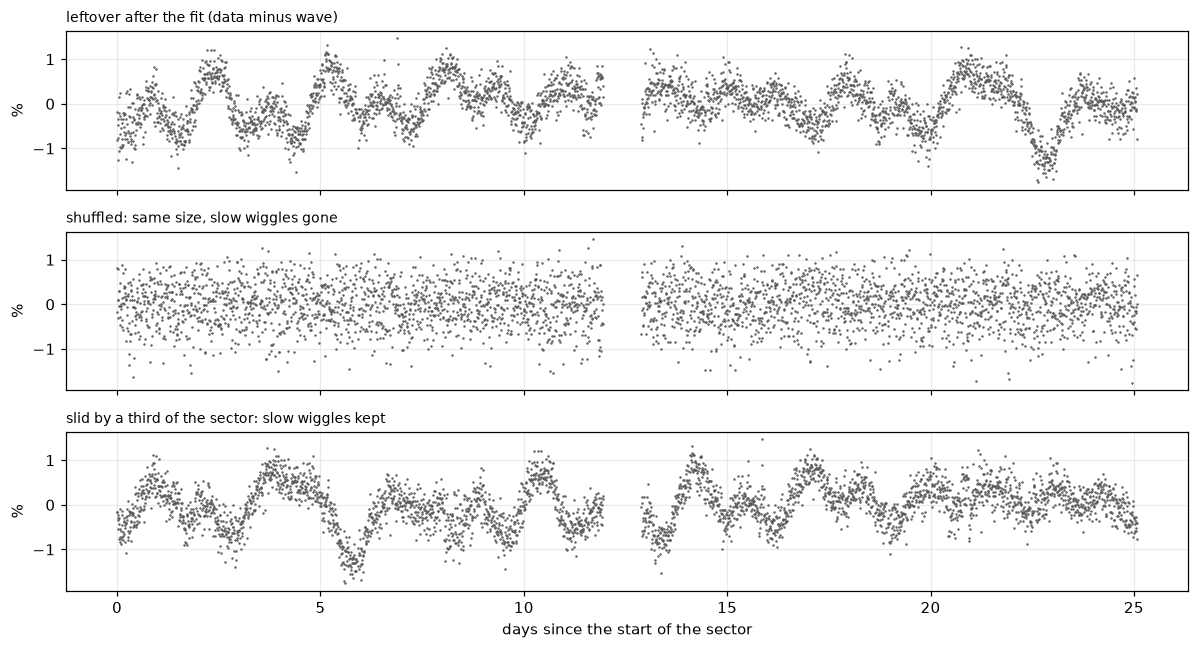

In [9]:
s = next(s for s in examples[sun_like["tic_id"]] if s["sector"] == 36)
x = s["time"] - s["time"][0]
rng = np.random.default_rng(1)
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, values, label in [
    (axes[0], s["leftover"], "leftover after the fit (data minus wave)"),
    (axes[1], rng.permutation(s["leftover"]), "shuffled: same size, slow wiggles gone"),
    (axes[2], np.roll(s["leftover"], len(x) // 3), "slid by a third of the sector: slow wiggles kept"),
]:
    ax.plot(x, 100 * values, ".", ms=1.2, color="0.35")
    ax.set_title(label, fontsize=9, loc="left")
    ax.set_ylabel("%")
axes[2].set_xlabel("days since the start of the sector")
fig.tight_layout()
fig.savefig(w.FIGURES / "fig4_leftover.png", dpi=150)

,star,teff,wander,floor_shuffled,floor_slid,excess_slid,wander_over_floor_slid
0,TIC 45468124,5558,0.0802,0.0016,0.0218,0.0772,3.6775
1,TIC 357118805,3372,0.0041,0.0021,0.0037,0.0017,1.0944


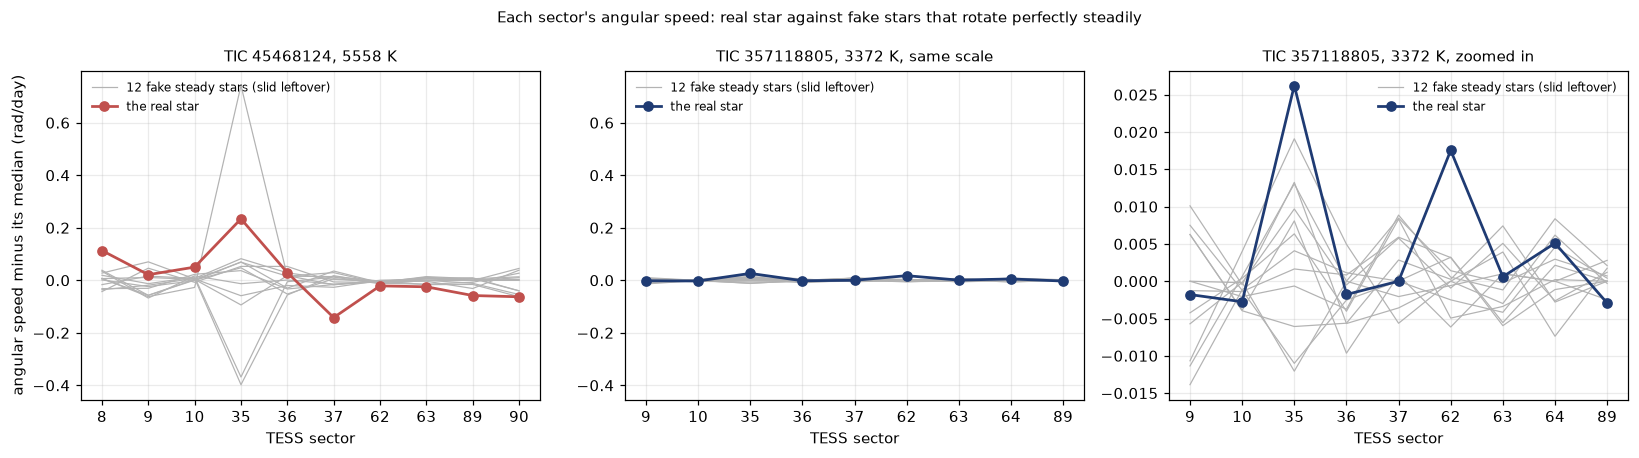

In [10]:
rows, runs_of = [], {}
for star in (sun_like, m_dwarf):
    sectors = examples[star["tic_id"]]
    wander = w.angular_mad([s["period"] for s in sectors])
    floor_white, _ = w.noise_floor(sectors, star["period"], star["tic_id"], "white")
    floor_shifted, runs_of[star["tic_id"]] = w.noise_floor(sectors, star["period"], star["tic_id"], "shifted")
    rows.append(dict(star=f"TIC {star['tic_id']}", teff=round(star["teff"]), wander=wander,
                     floor_shuffled=floor_white, floor_slid=floor_shifted,
                     excess_slid=np.sqrt(max(wander**2 - floor_shifted**2, 0)), wander_over_floor_slid=wander / floor_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, star, color, note in [(axes[0], sun_like, "#c0504d", ""), (axes[1], m_dwarf, "#1f3b73", ", same scale"),
                              (axes[2], m_dwarf, "#1f3b73", ", zoomed in")]:
    sectors = examples[star["tic_id"]]
    real = 2 * np.pi / np.array([s["period"] for s in sectors])
    positions = np.arange(len(sectors))
    for i, run in enumerate(runs_of[star["tic_id"]]):
        fake = 2 * np.pi / run
        ax.plot(positions, fake - np.nanmedian(fake), "-", color="0.7", lw=0.8,
                label="12 fake steady stars (slid leftover)" if i == 0 else None)
    ax.plot(positions, real - np.median(real), "o-", color=color, lw=1.8, label="the real star")
    ax.set_xticks(positions)
    ax.set_xticklabels([str(s["sector"]) for s in sectors])
    ax.set_xlabel("TESS sector")
    ax.set_title(f"TIC {star['tic_id']}, {star['teff']:.0f} K{note}", fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right" if note == ", zoomed in" else "upper left")
axes[1].set_ylim(axes[0].get_ylim())
axes[0].set_ylabel("angular speed minus its median (rad/day)")
fig.suptitle("Each sector's angular speed: real star against fake stars that rotate perfectly steadily", fontsize=10)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig5_real_vs_steady.png", dpi=150)
pd.DataFrame(rows).round(4)

For the Sun-like star most of the grey fake stars stay within about 0.05 rad/day of their median, apart from a few that jump in sector 35, while the real star is off by 0.1 to 0.23 rad/day in three of its ten sectors. Its wander is 3.7 times its slid floor.

On the same scale the M dwarf is a flat line, so the third panel zooms in about 30 times. The real star stays inside the band of its fakes in seven of its nine sectors. Sectors 35 and 62 stick out, but the wander uses the median deviation, so two odd sectors barely move it: 1.1 times the floor, which means almost all of the M dwarf's small wander is what noise alone would produce. Under the shuffled floor both ratios are larger, but the order is the same.

Section 6 does the same for every star.

## 6. All 872 stars

`w.measure_star` does sections 3 to 5 for one star: it fits every accepted sector, computes the wander, builds 12 shuffled and 12 slid fake stars, and returns one row. The fake stars use a fixed random seed plus the star's TIC number, so every run gives exactly the same numbers.

The results are saved in `results/stars_original.csv` and `results/stars_replication.csv`, and the cell below reads them. To measure everything again from the light curves, run `python get_data.py` (about 1 GB from MAST) and set `RECOMPUTE = True` at the top.

In [11]:
def measure_sample(list_name, out_csv):
    if out_csv.exists() and not RECOMPUTE:
        print(f"reading {out_csv.relative_to(w.ROOT)}")
        return pd.read_csv(out_csv)
    rows = w.read_star_list(list_name)
    start = time.time()
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 2)) as pool:
        measured = list(pool.map(w.measure_star, rows, chunksize=4))
    table = pd.DataFrame([m for m in measured if m is not None])
    table.to_csv(out_csv, index=False)
    print(f"{list_name}: measured {len(table)} of {len(rows)} stars in {(time.time() - start) / 60:.1f} min")
    return table

original_results = measure_sample("original_450", w.RESULTS / "stars_original.csv")
replication_results = measure_sample("replication_422", w.RESULTS / "stars_replication.csv")

reading results/stars_original.csv
reading results/stars_replication.csv


In [12]:
for name, table in [("original", original_results), ("replication", replication_results)]:
    print(f"{name}: {len(table)} stars, {table.sectors.sum()} sectors. Median wander {table.wander.median():.4f}, "
          f"median floor {table.floor_white.median():.4f} shuffled / {table.floor_shifted.median():.4f} slid (rad/day)")
original_results[["tic_id", "teff", "period", "sectors", "wander", "floor_white", "floor_shifted",
                  "ratio_shifted", "excess_shifted"]].head(8).round(4)

original: 450 stars, 4317 sectors. Median wander 0.0179, median floor 0.0023 shuffled / 0.0090 slid (rad/day)
replication: 422 stars, 4016 sectors. Median wander 0.0157, median floor 0.0026 shuffled / 0.0094 slid (rad/day)


,tic_id,teff,period,sectors,wander,floor_white,floor_shifted,ratio_shifted,excess_shifted
0,3544322,3018.0,4.1559,9,0.0295,0.0016,0.0087,3.3839,0.0282
1,31869488,3186.5,5.6584,15,0.0096,0.0046,0.0068,1.4010,0.0067
2,142319027,3197.1,1.8254,9,0.0119,0.0072,0.0073,1.6290,0.0094
3,154009241,3151.7,4.3203,9,0.0134,0.0044,0.0067,1.9859,0.0115
4,159652320,3178.8,3.8170,9,0.0119,0.0049,0.0086,1.3905,0.0083
5,160474395,3128.7,4.2196,14,0.0165,0.0095,0.0117,1.4155,0.0117
6,202510001,3145.3,2.7244,10,0.0081,0.0083,0.0098,0.8240,0.0000
7,219085997,3184.7,2.6831,8,0.0378,0.0094,0.0135,2.8062,0.0353


Every star in both samples had at least five usable sectors, so none was dropped: 4,317 sector light curves in the original sample and 4,016 in the replication. The columns are described in the README. [Part 2](2_results.ipynb) asks how these numbers depend on temperature.